# Wo, was und wann? Hauskauf in Seattle mit Daten entscheiden

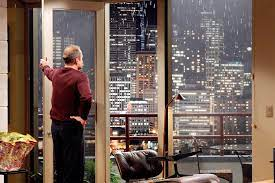

**Eine explorative Datenanalyse (EDA) für die Kundin Nicole Johnson, King County 2014/15**

## Fragestellung

Nicole Johnson möchte innerhalb eines Jahres ein Haus kaufen: **zentral und belebt**, in der **mittleren Preisklasse**, voraussichtlich allein lebend (2 bis 3 Zimmer, 1 bis 2 Bäder). Die Analyse beantwortet drei Fragen:

| Frage | Hypothese |
|---|---|
| **Wo?** | **Hypothese 3:** In einem definierten Abstand zur belebten Gegend sind Häuser bei ähnlicher Größe günstiger. |
| **Was?** | **Hypothese 2:** Kleinere Häuser sind in zentraler Lage günstiger als große. |
| **Wann?** | **Hypothese 1:** Die Preise im Innenstadtbereich steigen tendenziell, ein schneller Kauf könnte Geld sparen. |

## Datenquelle

Die Daten stammen aus einer PostgreSQL-Datenbank (King County House Sales, Mai 2014 bis Mai 2015, ca. 21.600 Verkäufe). Sie werden im Notebook `03_fetching_the_data_eda.ipynb` abgerufen und als `data/eda.csv` gespeichert. Die Datei liegt nicht im Repository (Zugangsdaten und Daten sind per `.gitignore` ausgeschlossen). Der Datensatz enthält keine Angabe zur Art der Immobilie, es handelt sich um Wohnimmobilienverkäufe.

## Inhalt

1. Daten laden und bereinigen
2. Kundenprofil: zentral, belebt, mittlere Preisklasse
3. Wo? Lage und Preis (Hypothese 3)
4. Was? Größe und Ausstattung (Hypothese 2)
5. Wann? Kaufzeitpunkt (Hypothese 1)
6. Empfehlung für Nicole Johnson

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import seaborn as sns
from plotly.subplots import make_subplots

warnings.filterwarnings("ignore")

pd.set_option("display.float_format", lambda x: "%.3f" % x)
plt.rcParams.update({"figure.figsize": (8, 5), "axes.facecolor": "white",
                     "axes.edgecolor": "black", "figure.facecolor": "w"})

SQFT_TO_SQM = 0.09290304                      # 1 sqft in m²
GRADE_LABELS = ["einfach (≤ 6)", "mittel (7)", "gehoben (≥ 8)"]
GRADE_PALETTE = ["#9AA9AD", "#3A7D8C", "#0B3C49"]   # hell bis dunkel
FIG_DIR = Path("figures")                     # Abbildungen für Präsentation und README
FIG_DIR.mkdir(exist_ok=True)


def save_fig(fig, name):
    """Speichert eine Matplotlib-Figur als PNG im Ordner figures/."""
    fig.savefig(FIG_DIR / f"{name}.png", dpi=200, bbox_inches="tight")

## 1. Daten laden und bereinigen

Die Bereinigung folgt dieser Reihenfolge: Struktur prüfen, doppelte Spalten und Zeilen entfernen, Datentypen setzen, fehlende Werte behandeln, Einheiten umrechnen, Spalten umbenennen und ordnen, offensichtliche Fehler korrigieren. Jede Annahme steht direkt vor dem zugehörigen Schritt.

In [3]:
df_houses = pd.read_csv("data/eda.csv")
print(df_houses.shape)
df_houses.head()

(21597, 23)


,date,price,house_id,id,id.1,bedrooms,bathrooms,sqft_living,sqft_lot,floors,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,2014-10-13,221900.000,7129300520,1,7129300520,3.000,1.000,1180.000,5650.000,1.000,...,7,1180.000,0.000,1955,0.000,98178,47.511,-122.257,1340.000,5650.000
1,2014-12-09,538000.000,6414100192,2,6414100192,3.000,2.250,2570.000,7242.000,2.000,...,7,2170.000,400.000,1951,19910.000,98125,47.721,-122.319,1690.000,7639.000
2,2015-02-25,180000.000,5631500400,3,5631500400,2.000,1.000,770.000,10000.000,1.000,...,6,770.000,0.000,1933,NaN,98028,47.738,-122.233,2720.000,8062.000
3,2014-12-09,604000.000,2487200875,4,2487200875,4.000,3.000,1960.000,5000.000,1.000,...,7,1050.000,910.000,1965,0.000,98136,47.521,-122.393,1360.000,5000.000
4,2015-02-18,510000.000,1954400510,5,1954400510,3.000,2.000,1680.000,8080.000,1.000,...,8,1680.000,0.000,1987,0.000,98074,47.617,-122.045,1800.000,7503.000


In [4]:
# Die Spalte 'id' ist nur eine fortlaufende Nummer (Index + 1) und trägt keine Information.
# Durch den Join der beiden Datenbanktabellen kann außerdem eine doppelte ID-Spalte ('id.1') entstanden sein.
if "id" in df_houses.columns:
    print("id entspricht Index + 1:", (df_houses["id"] == df_houses.index + 1).all())
df_houses = df_houses.drop(columns=[c for c in ["id", "id.1"] if c in df_houses.columns])

# Doppelte Zeilen? Dieselbe house_id mit unterschiedlichem Datum ist ein Wiederverkauf und kein Duplikat.
print("Komplett doppelte Zeilen:", df_houses.duplicated().sum())
print("Doppelte Verkäufe (gleiche house_id und gleiches Datum):", df_houses.duplicated(["house_id", "date"]).sum())

# Datentyp: Verkaufsdatum als Datum statt Text
df_houses["date"] = pd.to_datetime(df_houses["date"], format="%Y-%m-%d")
df_houses.dtypes

id entspricht Index + 1: True
Komplett doppelte Zeilen: 0
Doppelte Verkäufe (gleiche house_id und gleiches Datum): 0


date             datetime64[us]
price                   float64
house_id                  int64
bedrooms                float64
bathrooms               float64
sqft_living             float64
sqft_lot                float64
floors                  float64
waterfront              float64
view                    float64
condition                 int64
grade                     int64
sqft_above              float64
sqft_basement           float64
yr_built                  int64
yr_renovated            float64
zipcode                   int64
lat                     float64
long                    float64
sqft_living15           float64
sqft_lot15              float64
dtype: object

In [5]:
# Anzahl fehlender Werte pro Spalte
df_houses.isna().sum()

date                0
price               0
house_id            0
bedrooms            0
bathrooms           0
sqft_living         0
sqft_lot            0
floors              0
waterfront       2391
view               63
condition           0
grade               0
sqft_above          0
sqft_basement     452
yr_built            0
yr_renovated     3848
zipcode             0
lat                 0
long                0
sqft_living15       0
sqft_lot15          0
dtype: int64

### Fehlende Werte: `waterfront` und `view`

- `waterfront` ist ein 0/1-Merkmal. Ein fehlender Eintrag wird als **kein Seegrundstück (0)** gewertet.
- `view` ist eine Bewertung der Aussicht von 0 bis 4. Bei nur 63 fehlenden Werten ist es vertretbar, **keine besondere Aussicht (0)** anzunehmen. Ein Verkäufer würde die Angabe bei einer außergewöhnlichen Aussicht vermutlich nicht leer lassen.

In [6]:
print(df_houses["waterfront"].value_counts(dropna=False), "\n")
print(df_houses["view"].value_counts(dropna=False))

df_houses = df_houses.fillna({"waterfront": 0, "view": 0})

waterfront
0.000    19060
NaN       2391
1.000      146
Name: count, dtype: int64 

view
0.000    19422
2.000      957
3.000      508
1.000      330
4.000      317
NaN         63
Name: count, dtype: int64


### Fehlende Werte: `sqft_basement`

Es gibt zwei Möglichkeiten: Es gibt keinen Keller, dann ist `sqft_living = sqft_above`. Oder der Wert wurde nicht eingetragen, dann gilt `sqft_basement = sqft_living - sqft_above`. Beide Fälle deckt dieselbe Formel ab. Zuerst wird geprüft, ob sie bei den vorhandenen Werten stimmt.

In [7]:
mask = df_houses["sqft_basement"].notna()
anteil = (df_houses.loc[mask, "sqft_basement"]
          == df_houses.loc[mask, "sqft_living"] - df_houses.loc[mask, "sqft_above"]).mean()
print("Anteil der Zeilen, bei denen die Formel stimmt:", anteil)

df_houses["sqft_basement"] = df_houses["sqft_basement"].fillna(
    df_houses["sqft_living"] - df_houses["sqft_above"]
)
print("Verbleibende fehlende Werte:", df_houses["sqft_basement"].isna().sum())

Anteil der Zeilen, bei denen die Formel stimmt: 1.0
Verbleibende fehlende Werte: 0


### Fehlende Werte und falsche Skalierung: `yr_renovated`

- Die Werte stehen mit dem Faktor 10 in den Daten (z. B. `19910` statt `1991`). Sie werden durch 10 geteilt, aber nur dort, wo der Wert größer als 3000 ist. So lässt sich die Zelle gefahrlos mehrfach ausführen.
- Fehlende Werte (ca. 18 %) werden mit `0` gefüllt, das bedeutet **nicht renoviert**. Wie bei `waterfront` ist das eine Annahme.

In [9]:
vals = df_houses["yr_renovated"].dropna()
print("Alle positiven Werte durch 10 teilbar:", (vals[vals > 0] % 10 == 0).all())

df_houses.loc[df_houses["yr_renovated"] > 3000, "yr_renovated"] /= 10

# Kontrolle: Maximum höchstens ca. 2015, Minimum der echten Jahre nicht unter ca. 1900
print("Maximum:", df_houses["yr_renovated"].max())
print("Kleinstes Renovierungsjahr:", df_houses.loc[df_houses["yr_renovated"] > 0, "yr_renovated"].min())

df_houses["yr_renovated"] = df_houses["yr_renovated"].fillna(0).astype("Int64")

Alle positiven Werte durch 10 teilbar: False
Maximum: 2015
Kleinstes Renovierungsjahr: 1934


### Einheiten, Namen und Reihenfolge der Spalten

- Alle Flächen von Quadratfuß (`sqft`) in Quadratmeter (`sqm`) umrechnen.
- Die Spalten `sqm_living15` und `sqm_lot15` bedeuten die durchschnittliche Wohnfläche und Grundstücksgröße der 15 nächsten Nachbarn und erhalten einen eindeutigeren Namen.
- `date` wird zu `date_of_sale`, und die Spalten werden sinnvoll geordnet.

In [10]:
sqft_cols = [c for c in df_houses.columns if c.startswith("sqft_")]
df_houses[sqft_cols] = (df_houses[sqft_cols] * SQFT_TO_SQM).round(2)
df_houses = df_houses.rename(columns={c: c.replace("sqft_", "sqm_") for c in sqft_cols})

df_houses = df_houses.rename(columns={
    "sqm_lot15": "sqm_lot_neighbors_avg",
    "sqm_living15": "sqm_living_neighbors_avg",
    "date": "date_of_sale",
})

new_order = [
    "house_id", "date_of_sale", "price",
    "sqm_living", "sqm_lot", "sqm_above", "sqm_basement",
    "bedrooms", "bathrooms", "floors",
    "yr_built", "yr_renovated",
    "waterfront", "view", "condition", "grade",
    "zipcode", "lat", "long",
    "sqm_living_neighbors_avg", "sqm_lot_neighbors_avg",
]
assert set(new_order) == set(df_houses.columns), "Spaltenliste passt nicht zum DataFrame"
df_houses = df_houses[new_order]
df_houses.head()

,house_id,date_of_sale,price,sqm_living,sqm_lot,sqm_above,sqm_basement,bedrooms,bathrooms,floors,...,yr_renovated,waterfront,view,condition,grade,zipcode,lat,long,sqm_living_neighbors_avg,sqm_lot_neighbors_avg
0,7129300520,2014-10-13,221900.000,109.630,524.900,109.630,0.000,3.000,1.000,1.000,...,0,0.000,0.000,3,7,98178,47.511,-122.257,124.490,524.900
1,6414100192,2014-12-09,538000.000,238.760,672.800,201.600,37.160,3.000,2.250,2.000,...,1991,0.000,0.000,3,7,98125,47.721,-122.319,157.010,709.690
2,5631500400,2015-02-25,180000.000,71.540,929.030,71.540,0.000,2.000,1.000,1.000,...,0,0.000,0.000,3,6,98028,47.738,-122.233,252.700,748.980
3,2487200875,2014-12-09,604000.000,182.090,464.520,97.550,84.540,4.000,3.000,1.000,...,0,0.000,0.000,5,7,98136,47.521,-122.393,126.350,464.520
4,1954400510,2015-02-18,510000.000,156.080,750.660,156.080,0.000,3.000,2.000,1.000,...,0,0.000,0.000,3,8,98074,47.617,-122.045,167.230,697.050


### Ausreißer: 33 Schlafzimmer

Der Höchstwert bei `bedrooms` ist 33. Das passt weder zur Fläche noch zu den Bädern und ist vermutlich ein Tippfehler für 3.

In [11]:
spalten = ["house_id", "price", "bedrooms", "bathrooms", "sqm_living", "sqm_lot", "floors"]
print(df_houses.loc[df_houses["bedrooms"] == 33, spalten])

# 33 Schlafzimmer bei 150,5 m² und 1,75 Bädern ist vermutlich ein Tippfehler für 3
df_houses.loc[df_houses["house_id"] == 2402100895, "bedrooms"] = 3

df_houses.describe()

         house_id      price  bedrooms  bathrooms  sqm_living  sqm_lot  floors
15856  2402100895 640000.000    33.000      1.750     150.500  557.420   1.000


,house_id,date_of_sale,price,sqm_living,sqm_lot,sqm_above,sqm_basement,bedrooms,bathrooms,floors,...,yr_renovated,waterfront,view,condition,grade,zipcode,lat,long,sqm_living_neighbors_avg,sqm_lot_neighbors_avg
count,21597.000,21597,21597.000,21597.000,21597.000,21597.000,21597.000,21597.000,21597.000,21597.000,...,21597.000,21597.000,21597.000,21597.000,21597.000,21597.000,21597.000,21597.000,21597.000,21597.000
mean,4580474287.771,2014-10-29 04:20:38.171968,540296.574,193.268,1402.781,166.166,27.102,3.372,2.116,1.494,...,68.758,0.007,0.233,3.410,7.658,98077.952,47.560,-122.214,184.563,1185.283
min,1000102.000,2014-05-02 00:00:00,78000.000,34.370,48.310,34.370,0.000,1.000,0.500,1.000,...,0.000,0.000,0.000,1.000,3.000,98001.000,47.156,-122.519,37.070,60.480
25%,2123049175.000,2014-07-22 00:00:00,322000.000,132.850,468.230,110.550,0.000,3.000,1.750,1.000,...,0.000,0.000,0.000,3.000,7.000,98033.000,47.471,-122.328,138.430,473.810
50%,3904930410.000,2014-10-16 00:00:00,450000.000,177.440,707.740,144.930,0.000,3.000,2.250,1.500,...,0.000,0.000,0.000,3.000,7.000,98065.000,47.572,-122.231,170.940,707.920
75%,7308900490.000,2015-02-17 00:00:00,645000.000,236.900,992.670,205.320,52.030,4.000,2.500,2.000,...,0.000,0.000,0.000,4.000,8.000,98118.000,47.678,-122.125,219.250,936.740
max,9900000190.000,2015-05-27 00:00:00,7700000.000,1257.910,153416.270,874.220,447.790,11.000,8.000,3.500,...,2015.000,1.000,4.000,5.000,13.000,98199.000,47.778,-121.315,576.930,80937.130
std,2876735715.748,NaN,367368.140,85.295,3847.360,76.901,41.125,0.904,0.769,0.540,...,364.037,0.082,0.765,0.651,1.173,53.513,0.139,0.141,63.660,2533.879


In [12]:
# Kontrolle: keine fehlenden Werte mehr
print("Fehlende Werte gesamt:", int(df_houses.isna().sum().sum()))

# Bereinigte Daten sichern und mit einer Arbeitskopie weiterarbeiten
df_houses.to_csv("data/king_county_houses_clean.csv", index=False)
df_clean = df_houses.copy()

Fehlende Werte gesamt: 0


## 2. Kundenprofil: zentral, belebt, mittlere Preisklasse

**Annahmen zur Kundin**
- Sie sucht vermutlich allein, deshalb 2 bis 3 Zimmer und 1 bis 2 Bäder.
- Sie ist eventuell bereit, in einem gewissen Abstand zu den belebten Vierteln zu wohnen, wenn sich dadurch der Kaufpreis verringert.

**„Zentral und belebt“ muss messbar werden.** Eine Online-Recherche ergab diese Viertel:
- Seattle: Pioneer Square, Belltown, Capitol Hill, Fremont, Ballard
- Alternativen mit Cafés und Kultur, aber günstiger: Renton und Burien

Mögliche Ansätze, um die Viertel einzugrenzen:
1. **Zentrum von Seattle:** einfach, aber grob, und bildet die Alternativen nicht ab.
2. **Umkreis um mehrere Punkte (Koordinaten der Viertel):** bildet mehrere Zentren ab, die Auswahl ist aber subjektiv.
3. **Postleitzahlgebiete:** Daten liegen vor, die Grenzen sind aber grob.
4. **Bebauungsdichte (Grundstücksgrößen):** kleine Grundstücke deuten auf urbane Gebiete.

Gewählt wird **Ansatz 2**: Für jedes Haus wird die Luftlinie zum nächstgelegenen der oben genannten Orte (im Folgenden *Hubs*) berechnet. Dabei zählen alle sieben Orte als Hub, also auch Renton und Burien.

In [13]:
hubs = {
    "Pioneer Square": (47.6016, -122.3343),
    "Belltown":       (47.6141, -122.3453),
    "Capitol Hill":   (47.6200, -122.3210),
    "Fremont":        (47.6510, -122.3476),
    "Ballard":        (47.6770, -122.3850),
    # Alternativen zu Seattle mit lebhaftem, urbanem Charakter
    "Renton":         (47.483, -122.217),
    "Burien":         (47.4690, -122.3418),
}


def haversine_km(lat1, lon1, lat2, lon2):
    """Luftlinie in km zwischen zwei Koordinaten (Haversine-Formel)."""
    r = 6371
    p1, p2 = np.radians(lat1), np.radians(lat2)
    a = (np.sin((p2 - p1) / 2) ** 2
         + np.cos(p1) * np.cos(p2) * np.sin((np.radians(lon2) - np.radians(lon1)) / 2) ** 2)
    return 2 * r * np.arcsin(np.sqrt(a))


# Gibt es genug Häuser um jeden Hub? (Anzahl im Umkreis von 1, 2, 3 und 5 km)
for name, (la, lo) in hubs.items():
    d = haversine_km(df_clean["lat"], df_clean["long"], la, lo)
    print(f"{name:15s}", {r: int((d <= r).sum()) for r in (1, 2, 3, 5)})

Pioneer Square  {1: 0, 2: 49, 3: 327, 5: 1358}
Belltown        {1: 0, 2: 35, 3: 291, 5: 1453}
Capitol Hill    {1: 64, 2: 309, 3: 693, 5: 1414}
Fremont         {1: 142, 2: 468, 3: 879, 5: 2388}
Ballard         {1: 248, 2: 616, 3: 1045, 5: 2225}
Renton          {1: 45, 2: 143, 3: 331, 5: 1051}
Burien          {1: 46, 2: 190, 3: 316, 5: 784}


Diese Zählung hat einen Haken: Ein Haus nahe zwei Hubs wird mehrfach gezählt, und im inneren Kern (Pioneer Square, Belltown) gibt es kaum Verkäufe. Deshalb wird für jedes Haus **nur die Entfernung zum nächsten Hub** gespeichert (`dist_nearest_hub_km`). So zählt jedes Haus genau einmal.

In [14]:
# Entfernung jedes Hauses zu allen Hubs, dann der kleinste Wert je Haus
dist_df = pd.DataFrame({name: haversine_km(df_clean["lat"], df_clean["long"], la, lo)
                        for name, (la, lo) in hubs.items()})
df_clean["dist_nearest_hub_km"] = dist_df.min(axis=1)

print("Häuser im Umkreis des nächsten Hubs:")
for r in (1, 2, 3, 5):
    print(f"  bis {r} km: {int((df_clean['dist_nearest_hub_km'] <= r).sum())}")

Häuser im Umkreis des nächsten Hubs:
  bis 1 km: 545
  bis 2 km: 1779
  bis 3 km: 3036
  bis 5 km: 5616


### Mittlere Preisklasse

Der Begriff wird aus den Daten abgeleitet: Betrachtet werden Häuser mit höchstens 3 Zimmern, und als mittlere Preisklasse gelten die **mittleren 50 % der Verkaufspreise** (25 %-Quantil bis 75 %-Quantil). Zusätzlich wird der Preis pro m² berechnet, weil er unabhängig von der Hausgröße vergleichbar ist.

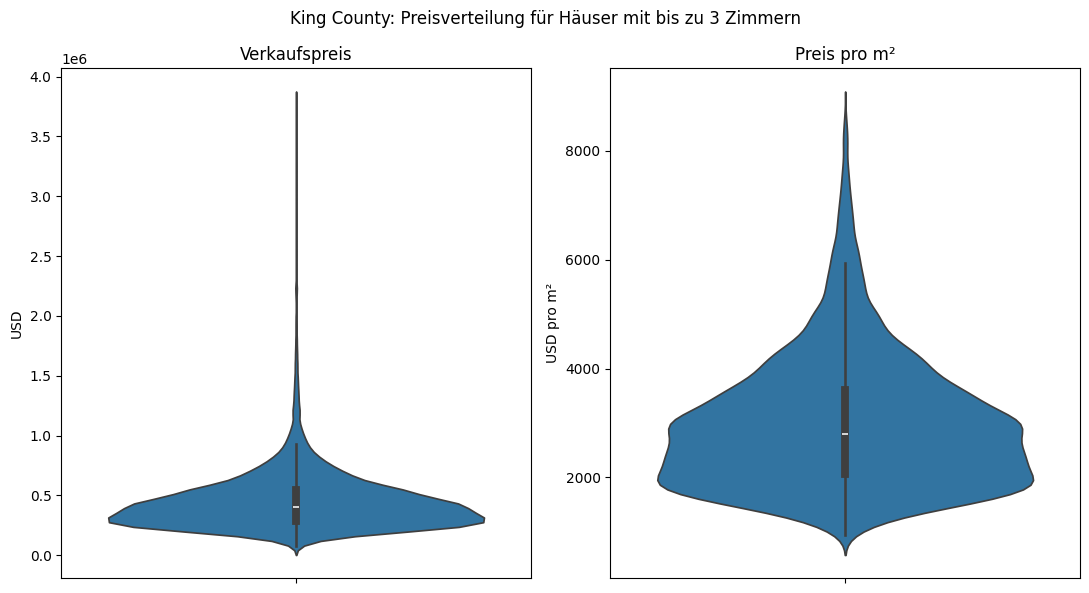

Mittlere Preisklasse: 289,000 bis 545,000 USD


In [15]:
df_clean["price_per_sqm"] = (df_clean["price"] / df_clean["sqm_living"]).round(2)

passend_county = df_clean[df_clean["bedrooms"].between(1, 3)]

fig, axes = plt.subplots(1, 2, figsize=(11, 6))
sns.violinplot(y=passend_county["price"], ax=axes[0])
axes[0].set_title("Verkaufspreis")
axes[0].set_ylabel("USD")
sns.violinplot(y=passend_county["price_per_sqm"], ax=axes[1])
axes[1].set_title("Preis pro m²")
axes[1].set_ylabel("USD pro m²")
fig.suptitle("King County: Preisverteilung für Häuser mit bis zu 3 Zimmern")
plt.tight_layout()
plt.show()

# Mittlere Preisklasse: 25 %- bis 75 %-Quantil des Verkaufspreises
price_low = passend_county["price"].quantile(0.25)
price_high = passend_county["price"].quantile(0.75)
print(f"Mittlere Preisklasse: {price_low:,.0f} bis {price_high:,.0f} USD")

### Passende Häuser für Nicole

Ein Haus passt zu Nicole, wenn es höchstens `radius_km` vom nächsten Hub entfernt liegt, 2 bis 3 Zimmer und 1 bis 2 Bäder hat und in der mittleren Preisklasse liegt. Die Funktion wird im Folgenden mehrfach verwendet. Die Karte zeigt die passenden Häuser im Umkreis von 5 km (schwarze Punkte sind die Hubs).

In [16]:
def filter_passend(df, radius_km):
    """Häuser im Umkreis von radius_km um den nächsten Hub, die zu Nicoles Wünschen passen."""
    zentral = df[df["dist_nearest_hub_km"] <= radius_km]
    passend = zentral[
        zentral["bedrooms"].between(2, 3)
        & zentral["bathrooms"].between(1, 2)
        & zentral["price"].between(price_low, price_high)
    ]
    return passend.assign(radius_km=f"≤ {radius_km} km")


passend = filter_passend(df_clean, 5)
print(f"{len(passend)} passende Häuser von {int((df_clean['dist_nearest_hub_km'] <= 5).sum())} im 5-km-Umkreis")

hub_df = pd.DataFrame([(n, la, lo) for n, (la, lo) in hubs.items()], columns=["name", "lat", "long"])

fig = px.scatter_map(
    passend, lat="lat", lon="long", color="price",
    hover_data=["price", "bedrooms", "bathrooms", "sqm_living", "dist_nearest_hub_km"],
    color_continuous_scale="Viridis", zoom=10, height=650, map_style="open-street-map",
)
fig.add_trace(go.Scattermap(lat=hub_df["lat"], lon=hub_df["long"], mode="markers",
                            marker=dict(size=18, color="black"), text=hub_df["name"],
                            name="Hubs", showlegend=True))
fig.write_html(FIG_DIR / "map_passende_haeuser.html", include_plotlyjs="cdn")
fig.show()

1150 passende Häuser von 5616 im 5-km-Umkreis


## 3. Wo? Lage und Preis (Hypothese 3)

**Hypothese 3:** In einem definierten Abstand (z. B. 1, 2, 3 oder 5 km) zur belebten Gegend sind die Häuser bei ähnlicher Größe günstiger.

Vorgehen: Die passenden Häuser werden nach ihrer Entfernung zum nächsten Hub in **getrennte Ringe** eingeteilt (0 bis 1, 1 bis 2, 2 bis 3 und 3 bis 5 km). Ringe, die sich nicht überschneiden, sind nötig, weil sich bei „bis 1 km“, „bis 2 km“ usw. die Daten der inneren Kreise in den äußeren wiederfinden würden und die Boxen sich dadurch stark überschneiden.

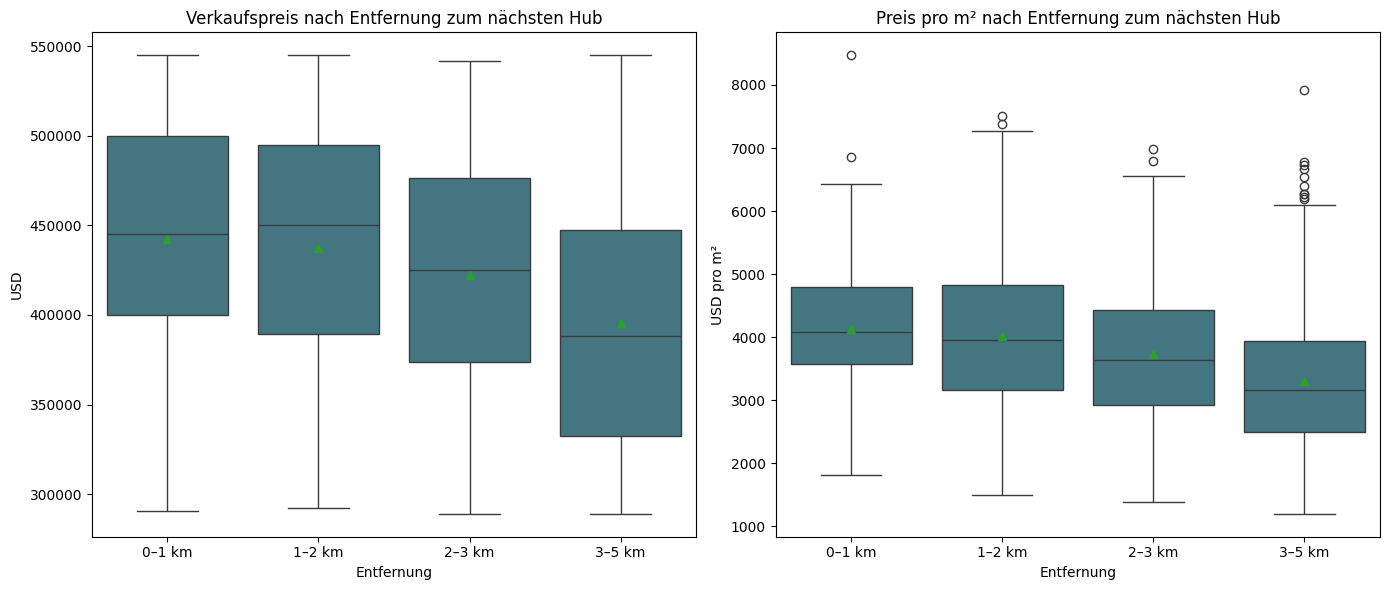

Häuser pro Ring:
ring
0–1 km    119
1–2 km    271
2–3 km    250
3–5 km    510
Name: count, dtype: int64


In [17]:
# Nicoles Filter ohne Radius anwenden, dann die Entfernung in Ringe einteilen
base = df_clean[
    df_clean["bedrooms"].between(2, 3)
    & df_clean["bathrooms"].between(1, 2)
    & df_clean["price"].between(price_low, price_high)
].copy()

ring_labels = ["0–1 km", "1–2 km", "2–3 km", "3–5 km"]
base["ring"] = pd.cut(base["dist_nearest_hub_km"], bins=[0, 1, 2, 3, 5], labels=ring_labels, include_lowest=True)
base = base.dropna(subset=["ring"])          # Häuser über 5 km entfallen

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sns.boxplot(data=base, x="ring", y="price", order=ring_labels, showmeans=True, color="#3A7D8C", ax=axes[0])
axes[0].set_title("Verkaufspreis nach Entfernung zum nächsten Hub")
axes[0].set_xlabel("Entfernung")
axes[0].set_ylabel("USD")
sns.boxplot(data=base, x="ring", y="price_per_sqm", order=ring_labels, showmeans=True, color="#3A7D8C", ax=axes[1])
axes[1].set_title("Preis pro m² nach Entfernung zum nächsten Hub")
axes[1].set_xlabel("Entfernung")
axes[1].set_ylabel("USD pro m²")
plt.tight_layout()
save_fig(fig, "h3_preis_nach_entfernung")
plt.show()

print("Häuser pro Ring:")
print(base["ring"].value_counts().reindex(ring_labels))

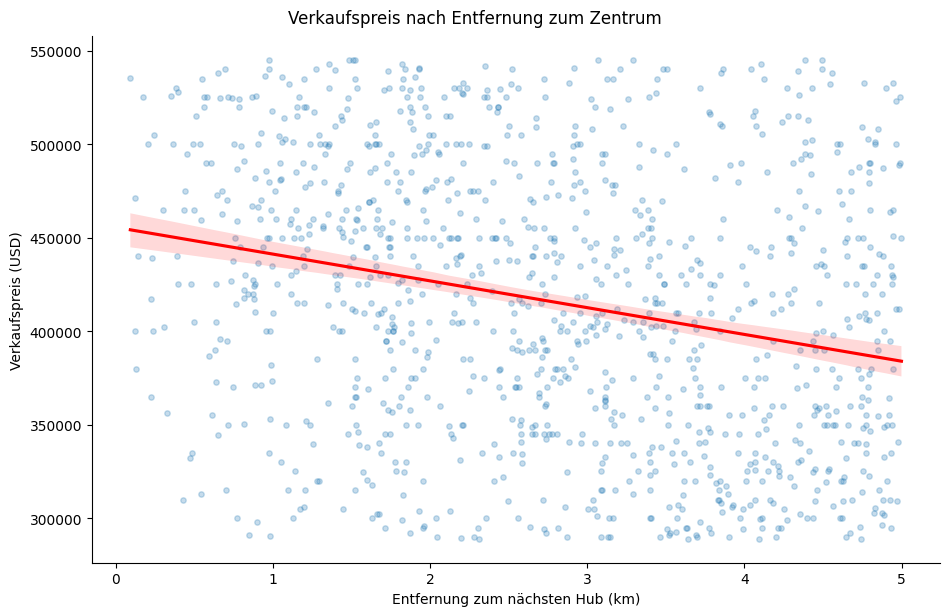

In [18]:
# Zusätzlich: Regressionsgerade über alle passenden Häuser im Umkreis von 5 km
g = sns.lmplot(data=passend, x="dist_nearest_hub_km", y="price", height=6, aspect=1.6,
               scatter_kws={"alpha": 0.25, "s": 15}, line_kws={"color": "red"})
g.set_axis_labels("Entfernung zum nächsten Hub (km)", "Verkaufspreis (USD)")
g.figure.suptitle("Verkaufspreis nach Entfernung zum Zentrum", y=1.02)
plt.show()

**Zusammenhänge im gesamten County:** Welche Merkmale hängen mit dem Preis zusammen? Die Korrelation nach Spearman misst den gemeinsamen Verlauf zweier Größen über Ränge und ist damit robust gegen Ausreißer. Sie zeigt nur den Zusammenhang, nicht die Ursache.

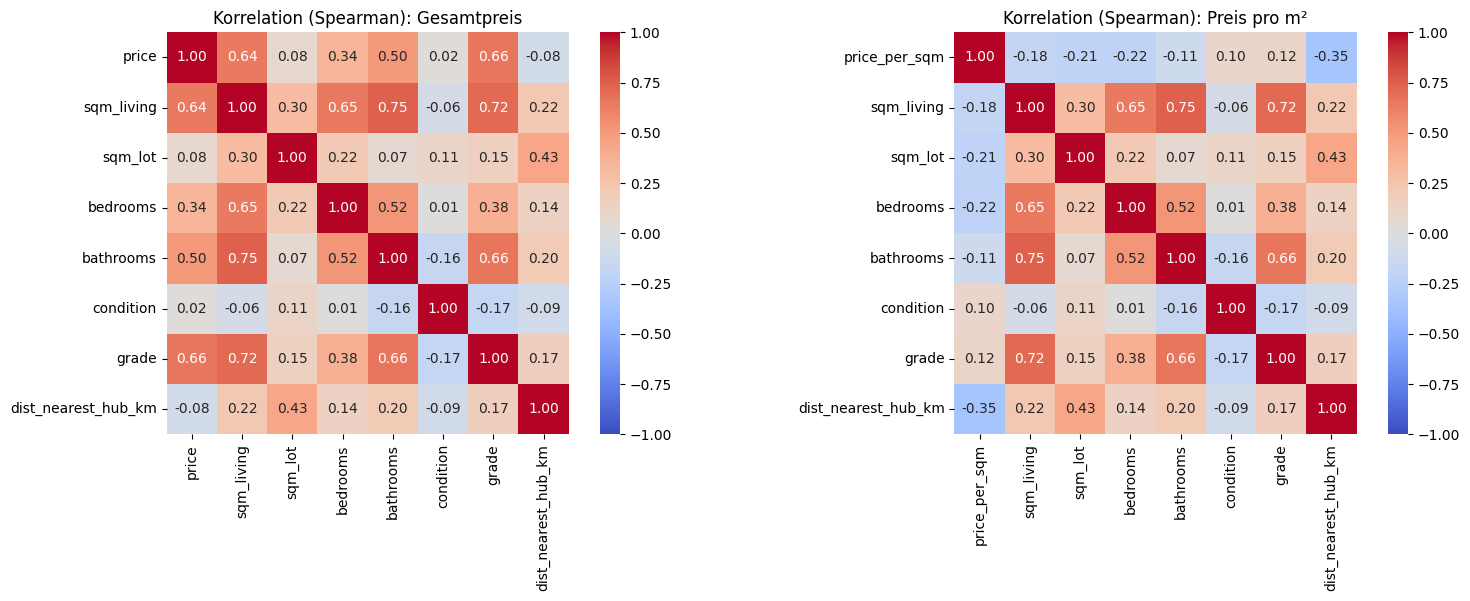

In [19]:
features = ["sqm_living", "sqm_lot", "bedrooms", "bathrooms", "condition", "grade", "dist_nearest_hub_km"]


def corr_heatmaps(data, features, name=None):
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    for ax, target, title in zip(axes, ["price", "price_per_sqm"], ["Gesamtpreis", "Preis pro m²"]):
        corr = data[[target] + features].corr(method="spearman")
        sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, center=0, square=True, ax=ax)
        ax.set_title(f"Korrelation (Spearman): {title}")
    plt.tight_layout()
    if name:
        save_fig(fig, name)
    plt.show()


corr_heatmaps(df_clean, features, "h3_korrelation_county")

### Zwischenfazit Hypothese 3

**Hypothese 3 wird teilweise bestätigt.** Je weiter ein Haus vom nächsten Hub entfernt liegt, desto günstiger ist es. Der Effekt ist mäßig und zeigt sich erst ab etwa 2 bis 3 km deutlich.

- **Ringe** (2 bis 3 Zimmer, 1 bis 2 Bäder, mittlere Preisklasse): Der Medianpreis liegt bis 2 km bei ca. 445.000 bis 450.000 USD, bei 2 bis 3 km bei ca. 425.000 USD und bei 3 bis 5 km bei ca. 388.000 USD. Der Preis pro m² sinkt von ca. 4.080 USD (0 bis 1 km) auf ca. 3.160 USD (3 bis 5 km).
- **Die Preise streuen in jedem Ring stark.** Die Entfernung allein erklärt daher nur einen kleinen Teil der Preisunterschiede. Weitere Einflussgrößen (Wohnfläche, Qualität, Baujahr) werden in Abschnitt 4 untersucht.
- **Einschränkung:** Der Filter auf die mittlere Preisklasse schneidet sehr teure und sehr günstige Häuser ab und schwächt den Zusammenhang dadurch eher ab.
- **Korrelationen im gesamten County:** Mit zunehmendem Abstand sinkt der Preis pro m² (−0,35), der Gesamtpreis aber kaum (−0,08). Der Grund steht in der Matrix: Die Entfernung hängt mit der Wohnfläche (0,22) und besonders mit der Grundstücksgröße (0,43) zusammen. Außerhalb sind die Häuser und Grundstücke größer, und der niedrigere Quadratmeterpreis wird durch mehr Fläche ausgeglichen. Nicole bekommt weiter draußen also vor allem mehr Platz fürs gleiche Geld, aber nicht ohne Weiteres einen niedrigeren Gesamtpreis.

## 4. Was? Größe und Ausstattung (Hypothese 2)

**Hypothese 2:** Kleinere Häuser sind in zentraler Lage günstiger als große.

Dafür wird das Teil-DataFrame `filtered_clean` gebildet: alle Häuser im Umkreis von **5 km** um den nächsten Hub und mit einem Preis bis 2 Mio. USD (die wenigen extremen Preise würden die Plots verzerren).

5561 Häuser im Umkreis von 5 km


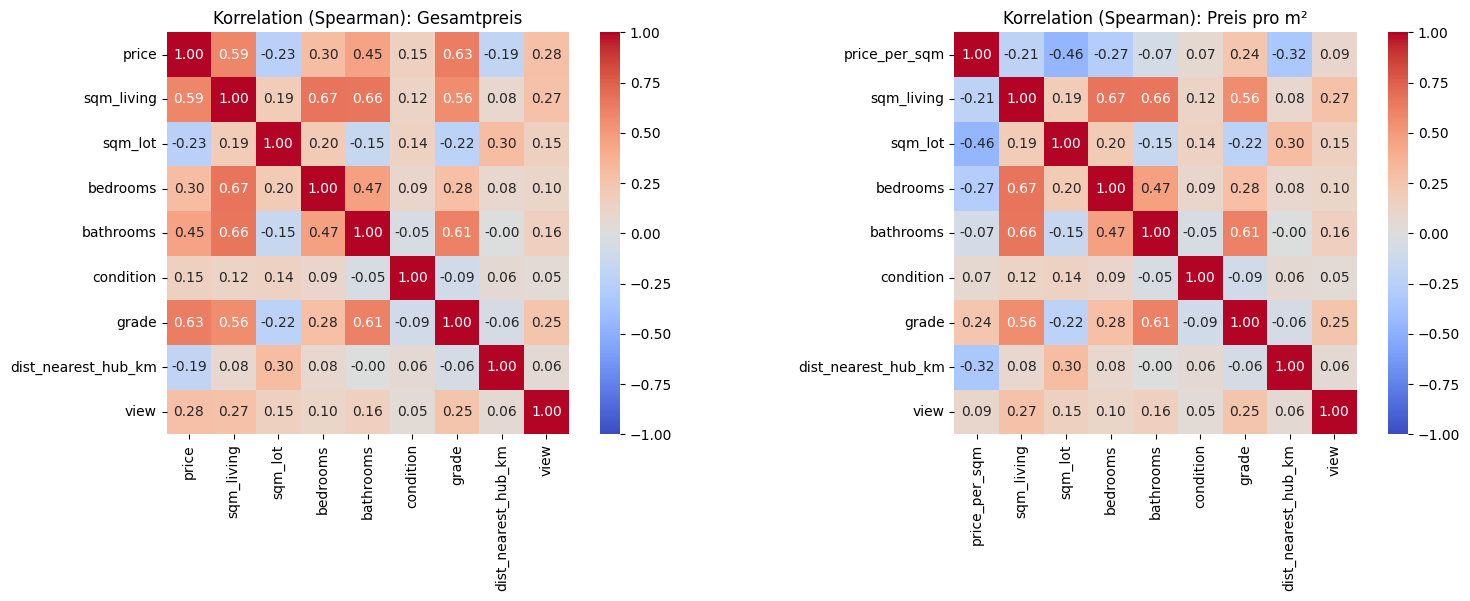

In [20]:
filtered_clean = df_clean[
    (df_clean["dist_nearest_hub_km"] <= 5)
    & df_clean["price"].between(0, 2e6)
].copy()
print(len(filtered_clean), "Häuser im Umkreis von 5 km")

corr_heatmaps(filtered_clean, features + ["view"], "h2_korrelation_5km")

**Was die Matrizen für den Umkreis von 5 km zeigen**

- **Gesamtpreis:** Am stärksten hängen die Qualität `grade` (0,63) und die Wohnfläche (0,59) mit dem Preis zusammen, danach `bathrooms` (0,45), `bedrooms` (0,30) und `view` (0,28). Die Entfernung zum Hub ist jetzt negativ korreliert (−0,19): Je näher am Zentrum, desto teurer. Große Grundstücke sind im Zentrum nicht teurer (`sqm_lot` −0,23).
- **Preis pro m²:** Der stärkste Zusammenhang besteht mit der Grundstücksgröße (−0,46), danach folgen die Entfernung (−0,32), die Zimmerzahl (−0,27) und die Wohnfläche (−0,21). Kleine Objekte sind pro m² teurer, große pro m² günstiger. `grade` ist leicht positiv (0,24). Dass die Wohnfläche im Nenner des m²-Preises steht, erklärt einen Teil der negativen Korrelation rechnerisch.
- **`condition`** hängt kaum mit dem Preis zusammen (0,15 bzw. 0,07). Eine Gruppierung nach dem Zustand lohnt sich daher nicht.
- Wohnfläche, Zimmer, Bäder und Qualität hängen untereinander stark zusammen (0,56 bis 0,67). Die Einzeleffekte lassen sich nur eingeschränkt trennen.

Die Häuser werden deshalb zunächst nach Wohnfläche gruppiert, anschließend zusätzlich nach Qualität.

size_group
< 50 m²          9
50–100 m²      790
100–150 m²    1856
150–200 m²    1379
> 200 m²      1527
Name: count, dtype: int64 



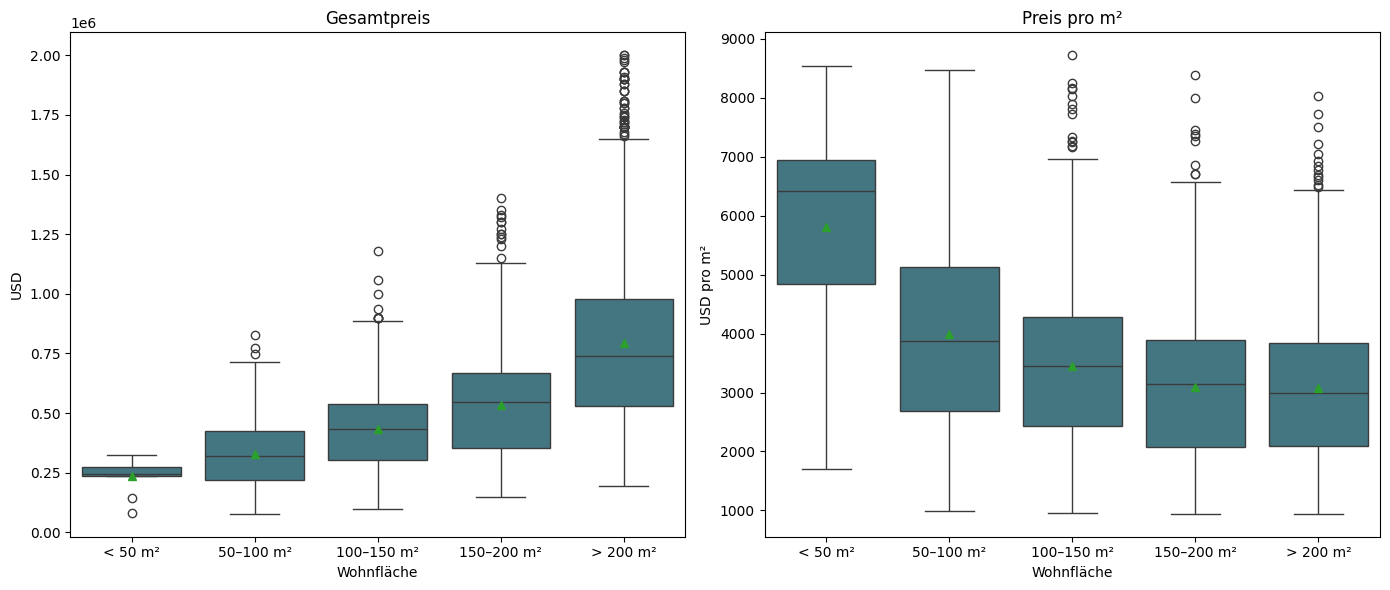

In [21]:
d = filtered_clean.copy()

# Größenklassen mit festen Grenzen (die Klassennamen sind die Bereiche)
size_bins = [0, 50, 100, 150, 200, np.inf]
size_labels = ["< 50 m²", "50–100 m²", "100–150 m²", "150–200 m²", "> 200 m²"]
d["size_group"] = pd.cut(d["sqm_living"], bins=size_bins, labels=size_labels, right=False)
print(d["size_group"].value_counts().reindex(size_labels), "\n")

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
sns.boxplot(data=d, x="size_group", y="price", order=size_labels, showmeans=True, color="#3A7D8C", ax=ax[0])
ax[0].set_title("Gesamtpreis")
ax[0].set_ylabel("USD")
sns.boxplot(data=d, x="size_group", y="price_per_sqm", order=size_labels, showmeans=True, color="#3A7D8C", ax=ax[1])
ax[1].set_title("Preis pro m²")
ax[1].set_ylabel("USD pro m²")
for a in ax:
    a.set_xlabel("Wohnfläche")
plt.tight_layout()
save_fig(fig, "h2_preis_nach_groesse")
plt.show()

- Der Gesamtpreis steigt mit der Wohnfläche: Median ca. 322.000 USD (50 bis 100 m²), 435.000 (100 bis 150 m²), 545.000 (150 bis 200 m²) und 739.000 (über 200 m²).
- Der Preis pro m² sinkt mit der Größe: ca. 3.870 → 3.450 → 3.150 → 2.990 USD.
- Die Klasse „< 50 m²“ enthält nur 9 Häuser und taugt nicht für eine Aussage.
- Die Streuung ist in jeder Klasse hoch. Das spricht dafür, dass weitere Effekte den Preis stark beeinflussen. Nach der Korrelationsmatrix hat die Qualität einen großen Einfluss. Deshalb werden die Häuser im nächsten Schritt zusätzlich nach `grade` in drei Gruppen eingeteilt: einfach (grade ≤ 6), mittel (grade = 7), gehoben (grade ≥ 8).

grade_group  einfach (≤ 6)  mittel (7)  gehoben (≥ 8)
size_group                                           
< 50 m²              9.000         NaN            NaN
50–100 m²          415.000     323.000         52.000
100–150 m²         314.000     992.000        550.000
150–200 m²          93.000     772.000        514.000
> 200 m²            14.000     442.000       1071.000 



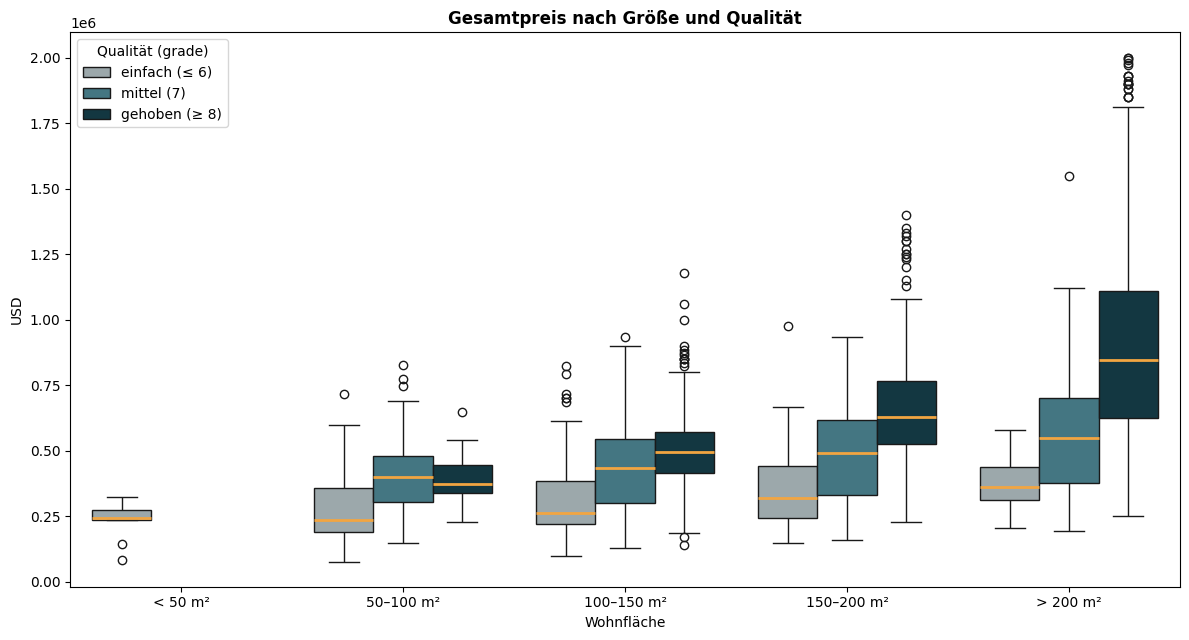

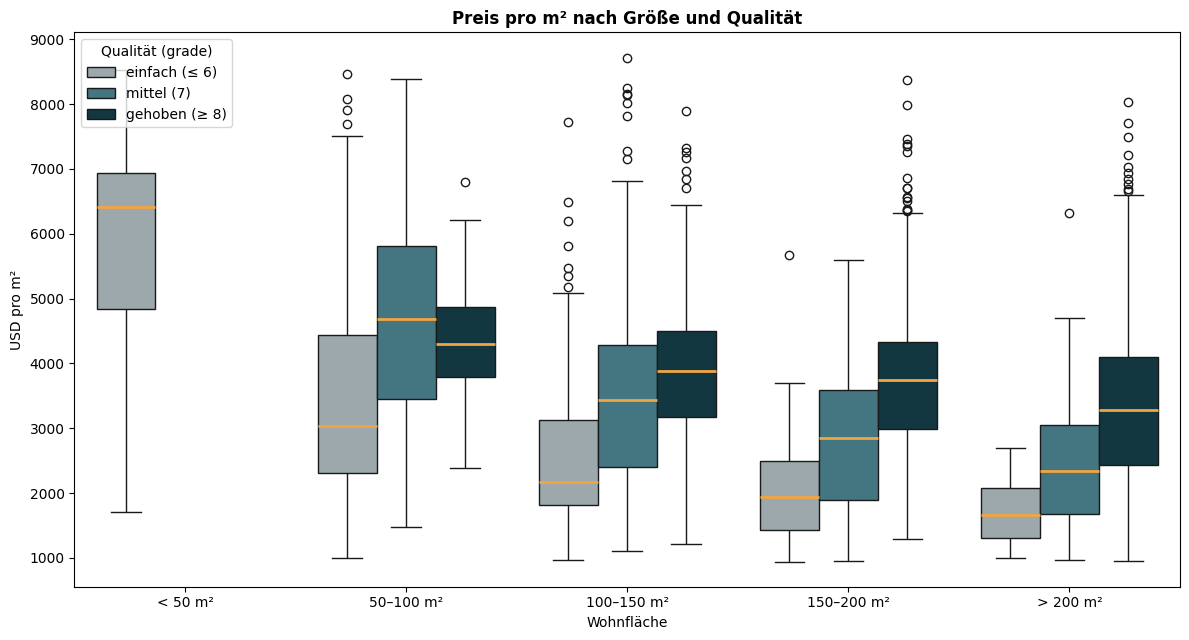

In [22]:
d["grade_group"] = pd.cut(d["grade"], bins=[0, 6, 7, 20], labels=GRADE_LABELS)
print(d.groupby(["size_group", "grade_group"], observed=True).size().unstack(), "\n")


def box_by_size_and_grade(data, y, title, ylabel, name):
    fig, ax = plt.subplots(figsize=(12, 6.5))
    sns.boxplot(data=data, x="size_group", y=y, hue="grade_group", order=size_labels,
                hue_order=GRADE_LABELS, palette=GRADE_PALETTE,
                medianprops={"color": "#F2A541", "linewidth": 2}, ax=ax)
    ax.set_title(title, fontweight="bold")
    ax.set_xlabel("Wohnfläche")
    ax.set_ylabel(ylabel)
    ax.legend(title="Qualität (grade)", loc="upper left")
    plt.tight_layout()
    save_fig(fig, name)
    plt.show()


box_by_size_and_grade(d, "price", "Gesamtpreis nach Größe und Qualität", "USD", "h2_preis_groesse_qualitaet")
box_by_size_and_grade(d, "price_per_sqm", "Preis pro m² nach Größe und Qualität", "USD pro m²", "h2_preis_m2_groesse_qualitaet")

- **Die Qualität ist der Haupttreiber.** Bei gleicher Größe liegen die Boxen von „einfach“ über „mittel“ zu „gehoben“ klar übereinander. Beispiel 150 bis 200 m²: Median ca. 320.000 (einfach), 493.000 (mittel) und 630.000 USD (gehoben).
- Bei **einfacher Ausstattung** steigt der Preis mit der Fläche nur langsam (Median ca. 235.000 USD bei 50 bis 100 m², ca. 363.000 USD bei über 200 m²), bei gehobener Ausstattung deutlich stärker (ca. 375.000 → 847.000 USD).
- Der **Preis pro m²** sinkt mit der Größe in allen Gruppen (z. B. „mittel“ von ca. 4.680 auf ca. 2.340 USD). Bei „einfach“ liegt er in den großen Klassen nur bei ca. 1.650 bis 1.940 USD, bei „gehoben“ fällt der Effekt schwächer aus.
- **Gruppengrößen:** „einfach“ über 200 m² hat nur 14 Häuser, „gehoben“ bei 50 bis 100 m² nur 52. Diese Gruppen sind wenig belastbar.

Als Nächstes wird geprüft, ob die Qualitätsgruppen gleich weit vom Zentrum entfernt liegen. Wenn ja, kommt der Preisunterschied nicht von der Lage.

               dist_nearest_hub_km  yr_built
grade_group                                 
einfach (≤ 6)                3.100  1942.000
mittel (7)                   2.900  1946.000
gehoben (≥ 8)                2.700  1984.000


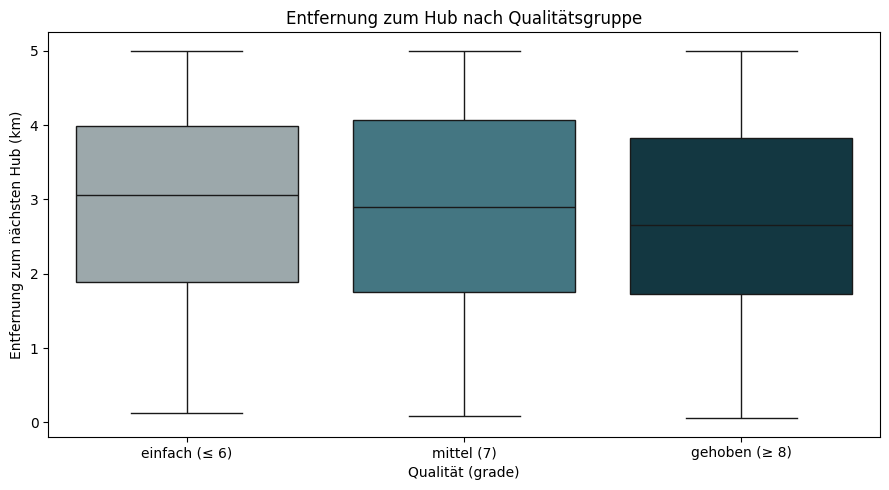

In [23]:
# Liegen die Qualitätsgruppen gleich weit vom Zentrum entfernt? Dann kommt der Preisunterschied nicht von der Lage.
print(d.groupby("grade_group", observed=True)[["dist_nearest_hub_km", "yr_built"]].median().round(1))

fig, ax = plt.subplots(figsize=(9, 5))
sns.boxplot(data=d, x="grade_group", y="dist_nearest_hub_km", order=GRADE_LABELS, palette=GRADE_PALETTE, ax=ax)
ax.set_xlabel("Qualität (grade)")
ax.set_ylabel("Entfernung zum nächsten Hub (km)")
ax.set_title("Entfernung zum Hub nach Qualitätsgruppe")
plt.tight_layout()
save_fig(fig, "h2_entfernung_nach_qualitaet")
plt.show()

### Beantwortung von Hypothese 2

Einfache, mittlere und gehobene Häuser liegen im Umkreis von 5 km ähnlich weit vom nächsten Hub entfernt (Median ca. 3,1, 2,9 und 2,7 km, die Boxen überlappen stark). Der Preisunterschied zwischen den Qualitätsgruppen kommt also nicht von der Lage, sondern von der Ausstattung. Gehobene Häuser sind allerdings deutlich jünger (Median Baujahr 1984 gegen 1942 bzw. 1946).

**Hypothese 2 (kleinere Häuser sind in zentraler Lage günstiger als große) wird teilweise bestätigt:**
- Der **Gesamtpreis** steigt in allen Qualitätsgruppen mit der Wohnfläche, kleinere Häuser sind also günstiger.
- Der **Preis pro m²** sinkt dagegen mit der Größe, kleine Häuser sind pro m² teurer.
- Die **Ausstattung** ist der stärkere Preistreiber als die Größe. Wer bei der Ausstattung Abstriche macht, bekommt in gleicher Lage mehr Wohnfläche für das gleiche Geld.

## 5. Wann? Kaufzeitpunkt (Hypothese 1)

**Hypothese 1:** Die Preise im Innenstadtbereich steigen tendenziell. Ein schneller Kauf könnte deshalb Geld sparen.

Vorgehen:
1. Entwicklung über die 13 Monate des Datensatzes, getrennt nach Qualitätsstufen.
2. Direkter Vergleich desselben Monats (Mai 2014 gegen Mai 2015).
3. Häuser, die im Beobachtungszeitraum zweimal verkauft wurden (Wiederverkäufe).

Grundlage sind die Häuser im Umkreis von 5 km, die zu Nicole passen (2 bis 3 Zimmer, 1 bis 2 Bäder, kein Seegrundstück). Der Preis wird bewusst nicht auf die mittlere Preisklasse beschränkt, weil ein Preisanstieg sonst abgeschnitten würde.

Häuser pro Monat und Qualität:
grade_group  einfach (≤ 6)  mittel (7)  gehoben (≥ 8)
month                                                
2014-05                 60         112             42
2014-06                 72         153             48
2014-07                 58         160             43
2014-08                 48         130             39
2014-09                 46         118             43
2014-10                 57         120             36
2014-11                 48         103             37
2014-12                 23          89             39
2015-01                 34          60             21
2015-02                 37          80             33
2015-03                 66         123             33
2015-04                 82         133             49
2015-05                 19          52             10


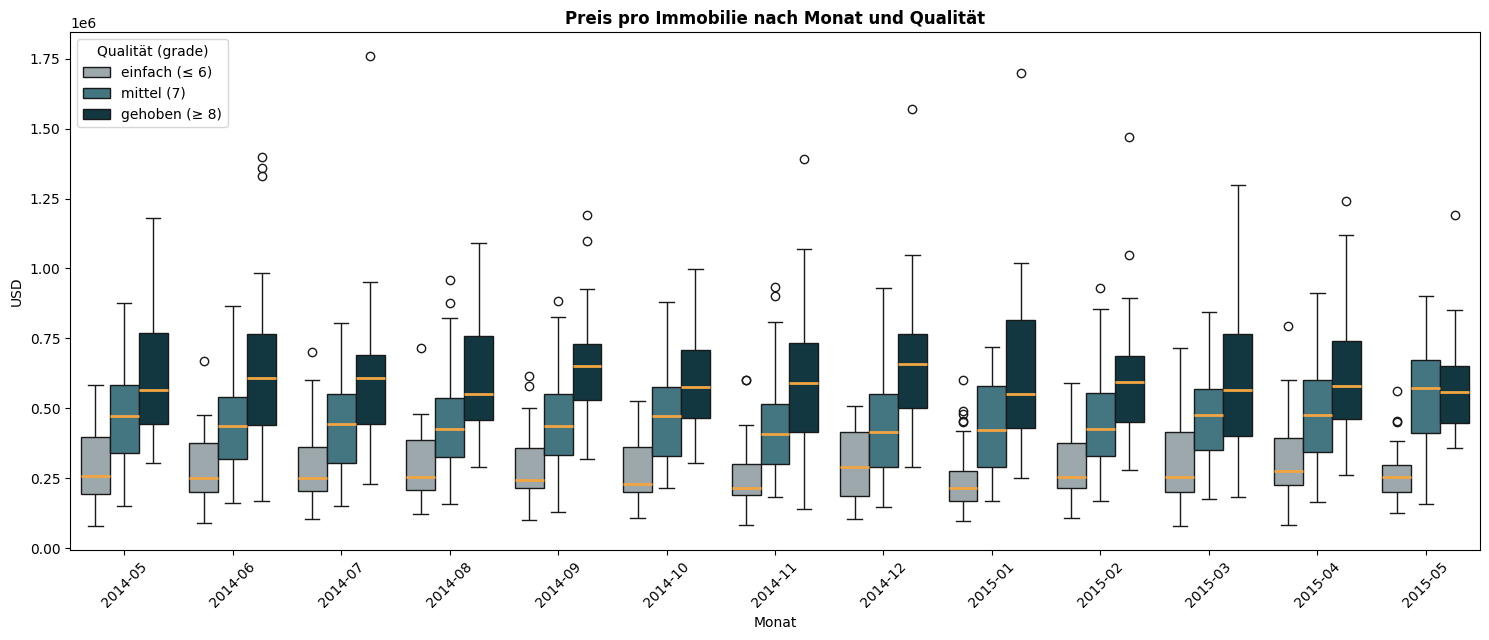

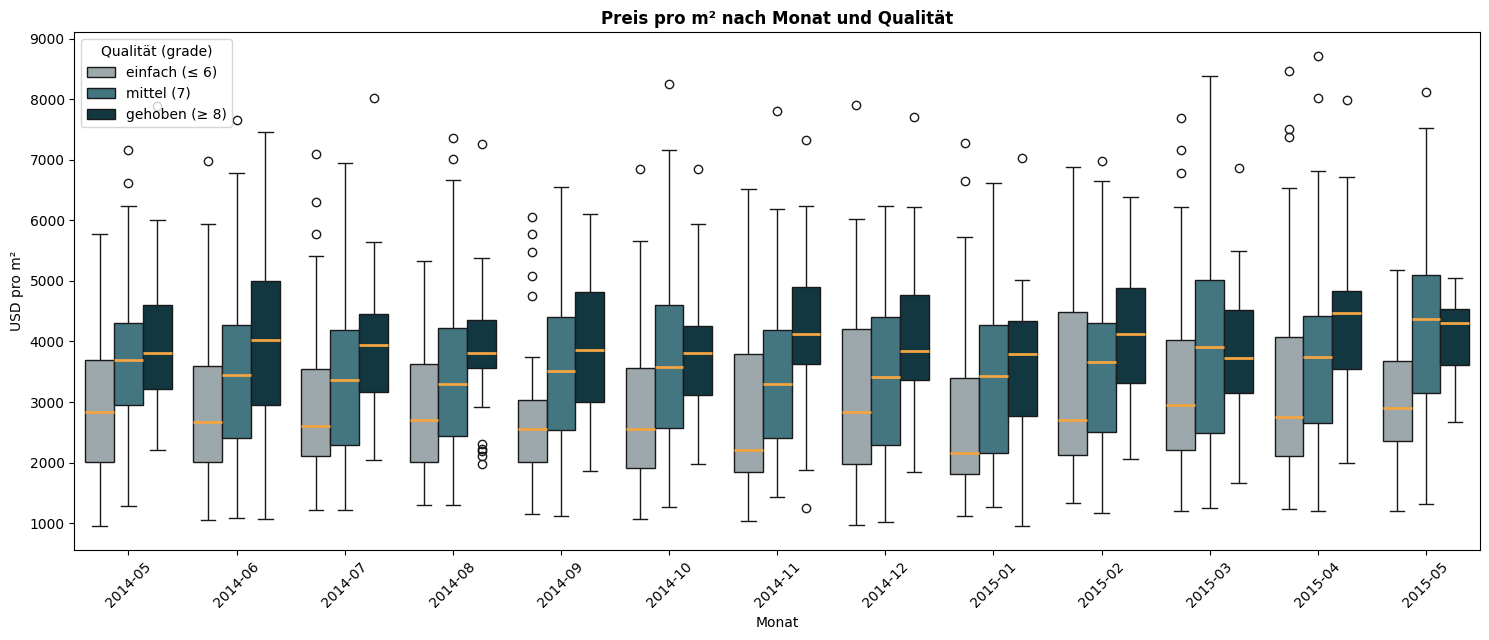

In [24]:
filtered_clean["month"] = filtered_clean["date_of_sale"].dt.to_period("M").astype(str)
month_order = sorted(filtered_clean["month"].unique())

nicole = filtered_clean[
    filtered_clean["bedrooms"].between(2, 3)
    & filtered_clean["bathrooms"].between(1, 2)
    & (filtered_clean["waterfront"] == 0)
].copy()
nicole["grade_group"] = pd.cut(nicole["grade"], bins=[0, 6, 7, 20], labels=GRADE_LABELS)

print("Häuser pro Monat und Qualität:")
print(nicole.groupby(["month", "grade_group"], observed=True).size().unstack())


def box_by_month(data, y, title, ylabel, name):
    fig, ax = plt.subplots(figsize=(15, 6.5))
    sns.boxplot(data=data, x="month", y=y, hue="grade_group", order=month_order,
                hue_order=GRADE_LABELS, palette=GRADE_PALETTE,
                medianprops={"color": "#F2A541", "linewidth": 2}, ax=ax)
    ax.set_title(title, fontweight="bold")
    ax.set_xlabel("Monat")
    ax.set_ylabel(ylabel)
    ax.tick_params(axis="x", rotation=45)
    ax.legend(title="Qualität (grade)", loc="upper left")
    plt.tight_layout()
    save_fig(fig, name)
    plt.show()


box_by_month(nicole, "price", "Preis pro Immobilie nach Monat und Qualität", "USD", "h1_preis_nach_monat")
box_by_month(nicole, "price_per_sqm", "Preis pro m² nach Monat und Qualität", "USD pro m²", "h1_preis_m2_nach_monat")

Über die 13 Monate bleiben die Medianpreise in allen drei Qualitätsstufen weitgehend konstant (einfach ca. 216.000 bis 290.000, mittel ca. 410.000 bis 475.000, gehoben ca. 550.000 bis 660.000 USD). Saisonale Muster, etwa günstigere Wintermonate, sind nicht erkennbar, und die Streuung innerhalb der Monate ist größer als die Unterschiede zwischen ihnen. Nur im mittleren Segment liegt der letzte Monat (Mai 2015) mit ca. 572.500 USD deutlich über den Vormonaten (ca. 475.000 USD).

Generelle Preisentwicklungen lassen sich am direktesten durch den Vergleich desselben Monats ablesen (Mai 2014 gegen Mai 2015), weil er genau ein Jahr umfasst.

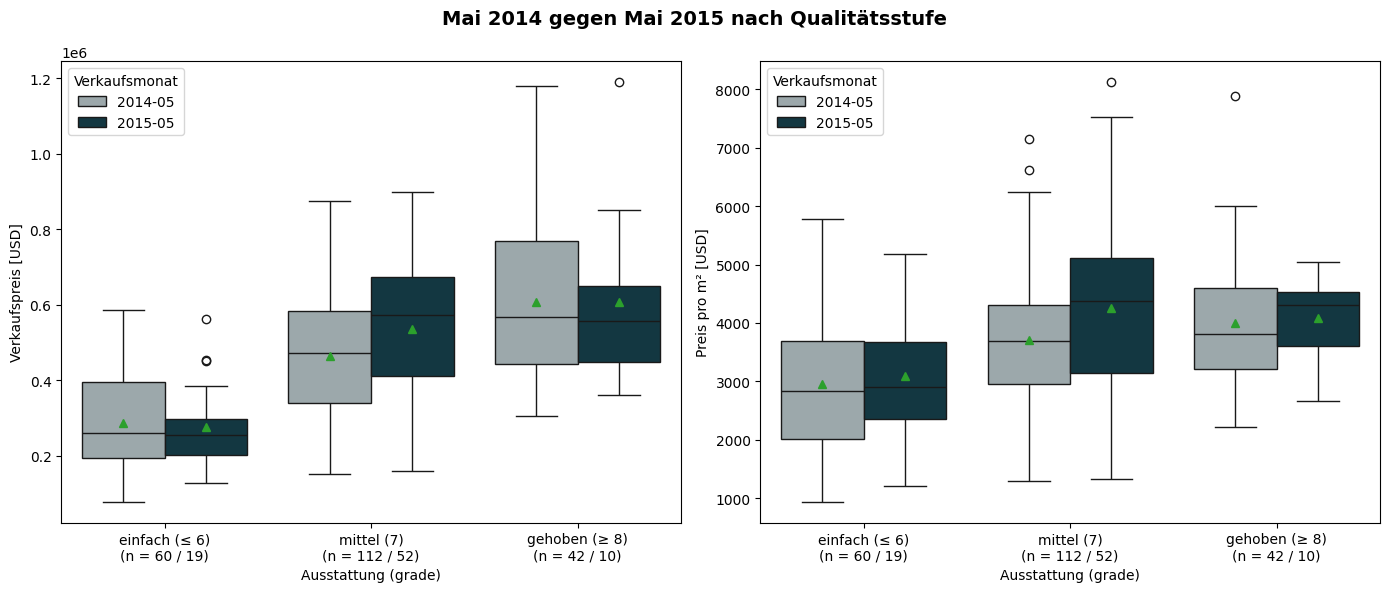

,Median Preis 2014,Median Preis 2015,Änderung Preis (%),Median Preis/m² 2014,Median Preis/m² 2015,Änderung Preis/m² (%),n 2014,n 2015
grade_group,,,,,,,,
einfach (≤ 6),258500.000,255000.000,-1.000,2834.000,2896.000,2.000,60,19
mittel (7),472000.000,572500.000,21.000,3688.000,4374.000,19.000,112,52
gehoben (≥ 8),567500.000,557500.000,-2.000,3811.000,4299.000,13.000,42,10


In [23]:
# Vergleich desselben Monats: Mai 2014 gegen Mai 2015, getrennt nach Qualität
may = nicole[nicole["month"].isin(["2014-05", "2015-05"])].copy()
n = may.groupby(["grade_group", "month"], observed=True).size().unstack()

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
for a, y, ylabel in zip(ax, ["price", "price_per_sqm"], ["Verkaufspreis [USD]", "Preis pro m² [USD]"]):
    sns.boxplot(data=may, x="grade_group", y=y, hue="month", order=GRADE_LABELS,
                hue_order=["2014-05", "2015-05"], palette=["#9AA9AD", "#0B3C49"],
                showmeans=True, ax=a)
    a.set_xlabel("Ausstattung (grade)")
    a.set_ylabel(ylabel)
    a.legend(title="Verkaufsmonat", loc="upper left")
    a.set_xticklabels([f"{g}\n(n = {n.loc[g, '2014-05']} / {n.loc[g, '2015-05']})" for g in GRADE_LABELS])
fig.suptitle("Mai 2014 gegen Mai 2015 nach Qualitätsstufe", fontsize=14, fontweight="bold")
plt.tight_layout()
save_fig(fig, "h1_mai_vergleich")
plt.show()

# Kennzahlen als Tabelle
g = may.groupby(["grade_group", "month"], observed=True)
med_price = g["price"].median().unstack()
med_sqm = g["price_per_sqm"].median().unstack()
summary = pd.DataFrame({
    "Median Preis 2014": med_price["2014-05"],
    "Median Preis 2015": med_price["2015-05"],
    "Änderung Preis (%)": (med_price["2015-05"] / med_price["2014-05"] - 1) * 100,
    "Median Preis/m² 2014": med_sqm["2014-05"],
    "Median Preis/m² 2015": med_sqm["2015-05"],
    "Änderung Preis/m² (%)": (med_sqm["2015-05"] / med_sqm["2014-05"] - 1) * 100,
    "n 2014": n["2014-05"],
    "n 2015": n["2015-05"],
})
summary.round(0).astype({"n 2014": int, "n 2015": int})

| Qualität | Median Preis 2014 → 2015 | Änderung | Median Preis/m² | n 2014 → 2015 |
| --- | --- | --- | --- | --- |
| einfach | 258.500 → 255.000 | −1 % | 2.834 → 2.896 (+2 %) | 60 → 19 |
| mittel | 472.000 → 572.500 | +21 % | 3.688 → 4.374 (+19 %) | 112 → 52 |
| gehoben | 567.500 → 557.500 | −2 % | 3.811 → 4.299 (+13 %) | 42 → 10 |

Ein deutlicher Anstieg zeigt sich nur in der Qualitätsstufe „mittel“. Er beruht im Monatsverlauf vor allem auf dem letzten Monat (Mai 2015), die Monate davor liegen bei ca. 475.000 USD. Die Gruppen sind klein (gehoben 2015: n = 10), und es werden nur zwei Zeitpunkte verglichen. Die These steigender Preise lässt sich daher nicht eindeutig bestätigen.

Um den Preisanstieg weiter zu untersuchen, werden als Nächstes Häuser betrachtet, die im Beobachtungszeitraum zweimal verkauft wurden.

### Wiederverkäufe

Häuser, die innerhalb des Beobachtungszeitraums zweimal verkauft wurden, haben dieselbe Größe und Lage. Der Preisunterschied zwischen erstem und letztem Verkauf zeigt die Preisentwicklung daher ohne den Einfluss unterschiedlicher Häuser. Es gibt nur wenige davon, deshalb wird das gesamte County betrachtet.

In [25]:
# Häuser mit mehr als einem Verkauf, chronologisch sortiert
sales = df_clean.sort_values(["house_id", "date_of_sale"])
repeat = sales[sales.duplicated("house_id", keep=False)].copy()

# Je Haus: erster und letzter Verkauf (Datum und Preis) sowie Anzahl der Verkäufe
resale = repeat.groupby("house_id").agg(
    first_date=("date_of_sale", "first"),
    last_date=("date_of_sale", "last"),
    first_price=("price", "first"),
    last_price=("price", "last"),
    n_sales=("price", "size"),
).reset_index()

resale["days_between"] = (resale["last_date"] - resale["first_date"]).dt.days
resale["pct_change"] = (resale["last_price"] / resale["first_price"] - 1) * 100

# Qualität (grade) gehört zum Haus und wird über die house_id ergänzt
info = df_clean.drop_duplicates("house_id")[["house_id", "grade", "lat", "long", "dist_nearest_hub_km"]]
resale = resale.merge(info, on="house_id", how="left")
resale["grade_group"] = pd.cut(resale["grade"], bins=[0, 6, 7, 20], labels=GRADE_LABELS)

print(len(resale), "Häuser mit Wiederverkauf")
print("Anteil mit Preisanstieg:", round((resale["pct_change"] > 0).mean(), 2))
print(resale.groupby("grade_group", observed=True)["pct_change"]
            .agg(n="size", median="median", mean="mean",
                 q25=lambda s: s.quantile(0.25), q75=lambda s: s.quantile(0.75)).round(1))

176 Häuser mit Wiederverkauf
Anteil mit Preisanstieg: 0.95
                n  median   mean    q25    q75
grade_group                                   
einfach (≤ 6)  50  61.900 75.300 37.500 90.200
mittel (7)     85  61.500 62.300 43.100 75.900
gehoben (≥ 8)  41   7.300 22.700  1.400 41.900


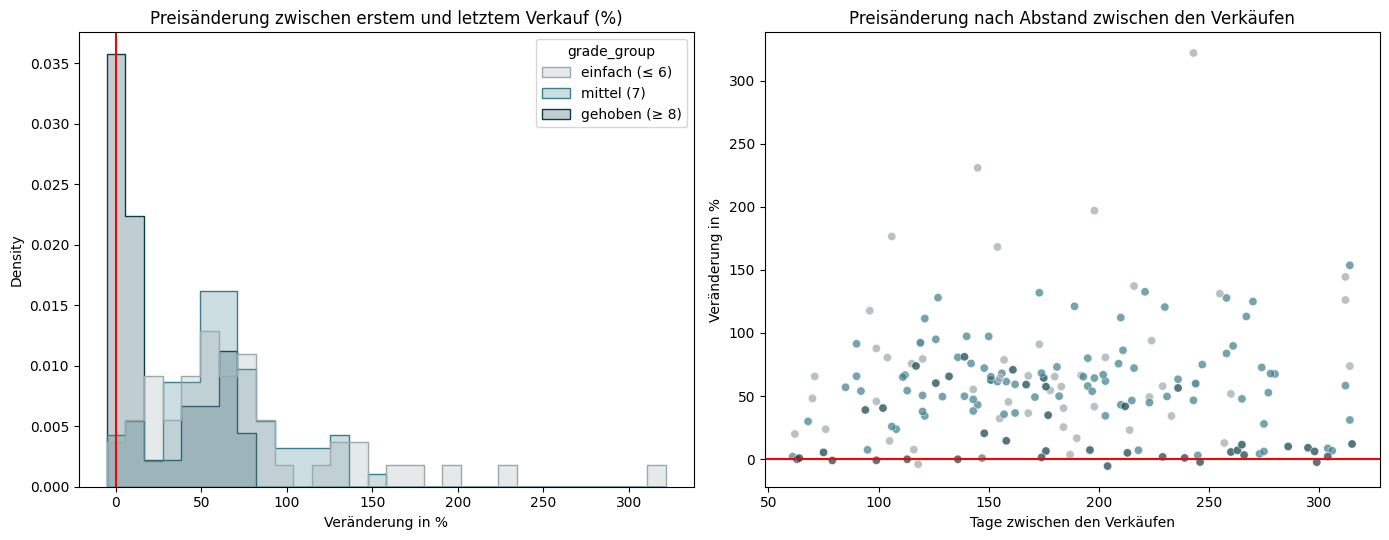

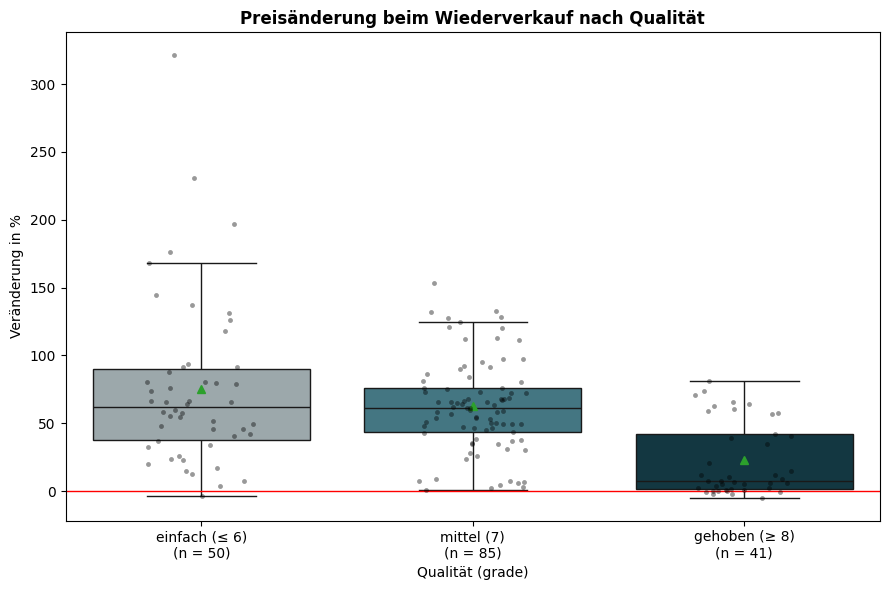

In [26]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
sns.histplot(data=resale, x="pct_change", hue="grade_group", hue_order=GRADE_LABELS, bins=30,
             stat="density", common_norm=False, element="step", palette=GRADE_PALETTE, ax=ax[0])
ax[0].axvline(0, color="red")
ax[0].set_title("Preisänderung zwischen erstem und letztem Verkauf (%)")
ax[0].set_xlabel("Veränderung in %")
sns.scatterplot(data=resale, x="days_between", y="pct_change", hue="grade_group",
                hue_order=GRADE_LABELS, alpha=0.7, palette=GRADE_PALETTE, ax=ax[1])
ax[1].axhline(0, color="red")
ax[1].set_title("Preisänderung nach Abstand zwischen den Verkäufen")
ax[1].set_xlabel("Tage zwischen den Verkäufen")
ax[1].set_ylabel("Veränderung in %")
ax[1].get_legend().remove()
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(9, 6))
sns.boxplot(data=resale, x="grade_group", y="pct_change", order=GRADE_LABELS, palette=GRADE_PALETTE,
            showmeans=True, showfliers=False, ax=ax)
sns.stripplot(data=resale, x="grade_group", y="pct_change", order=GRADE_LABELS,
              color="black", alpha=0.4, size=3.5, jitter=0.2, ax=ax)
ax.axhline(0, color="red", linewidth=1)
ax.set_title("Preisänderung beim Wiederverkauf nach Qualität", fontweight="bold")
ax.set_xlabel("Qualität (grade)")
ax.set_ylabel("Veränderung in %")
counts = resale["grade_group"].value_counts()
ax.set_xticklabels([f"{g}\n(n = {counts[g]})" for g in GRADE_LABELS])
plt.tight_layout()
save_fig(fig, "h1_wiederverkaeufe")
plt.show()

- Von den 176 Häusern mit Wiederverkauf hatten 95 % einen Preisanstieg. Der Median der Veränderung liegt bei ca. 62 % („einfach“, n = 50) und ca. 62 % („mittel“, n = 85), bei „gehoben“ (n = 41) nur bei ca. 7 %.
- Solche Sprünge sind für eine reine Marktentwicklung in weniger als einem Jahr unplausibel hoch. Vermutlich spielen Aufwertungen (Kauf, Sanierung, Weiterverkauf) eine Rolle. Das ist eine Vermutung: Eingetragene Renovierungen erklären die Sprünge nicht, und Änderungen von `grade` und `condition` lassen sich im Datensatz nicht messen, weil diese Merkmale nur einmal pro Haus gespeichert sind.
- Die Wiederverkäufe sind daher kein sauberes Signal für die Marktentwicklung.

**Liegen die Häuser mit starkem Anstieg im Zentrum?** Die Karten zeigen die Preisänderung der Wiederverkäufe nach Qualitätsstufe (gleiche Farbskala, Hubs als schwarze Punkte). Plotly-Karten sind interaktiv und erscheinen auf GitHub nicht in der Notebook-Ansicht. Sie liegen deshalb zusätzlich als HTML-Datei im Ordner `figures/`.

In [26]:
resale_geo = resale.dropna(subset=["lat", "long", "grade_group"]).copy()

titles = [f"{g} (n = {(resale_geo['grade_group'] == g).sum()})" for g in GRADE_LABELS]
fig = make_subplots(rows=1, cols=3, specs=[[{"type": "map"}] * 3],
                    subplot_titles=titles, horizontal_spacing=0.01)

for i, grp in enumerate(GRADE_LABELS, start=1):
    sub = resale_geo[resale_geo["grade_group"] == grp]
    fig.add_trace(
        go.Scattermap(
            lat=sub["lat"], lon=sub["long"], mode="markers",
            marker=dict(size=11, opacity=0.85, color=sub["pct_change"],
                        colorscale="YlOrRd", cmin=0, cmax=100,
                        showscale=(i == 3), colorbar=dict(title="Änderung (%)")),
            customdata=sub[["first_price", "last_price", "days_between"]],
            hovertemplate=("Änderung: %{marker.color:.0f} %<br>"
                           "Erster Preis: %{customdata[0]:,.0f}<br>"
                           "Letzter Preis: %{customdata[1]:,.0f}<br>"
                           "Tage dazwischen: %{customdata[2]}<extra></extra>"),
            showlegend=False,
        ),
        row=1, col=i,
    )
    fig.add_trace(
        go.Scattermap(lat=hub_df["lat"], lon=hub_df["long"], mode="markers",
                      marker=dict(size=14, color="black"), text=hub_df["name"],
                      name="Hubs", showlegend=(i == 1)),
        row=1, col=i,
    )

fig.update_maps(style="carto-positron", center=dict(lat=47.55, lon=-122.25), zoom=8)
fig.update_layout(height=650, margin=dict(l=0, r=0, t=40, b=0))
fig.write_html(FIG_DIR / "map_wiederverkaeufe.html", include_plotlyjs="cdn")
fig.show()

### Beantwortung von Hypothese 1

**Ergebnis:** Die Hypothese wird durch die Daten insgesamt nicht bestätigt. Nur im mittleren Ausstattungssegment („mittel“, grade 7) gibt es einen Hinweis auf steigende Preise, in den Segmenten „einfach“ und „gehoben“ blieben die Preise stabil. Ein schneller Kauf lässt sich daraus nicht ableiten.

1. **Entwicklung über das Jahr** (Umkreis ≤ 5 km um die Hubs, 2 bis 3 Zimmer, 1 bis 2 Bäder, ohne Seegrundstücke, nach Qualität): Die Medianpreise bleiben in allen drei Stufen weitgehend konstant, saisonale Schwankungen sind nicht erkennbar. Im mittleren Segment liegt nur der letzte Monat deutlich höher. Ob das den Beginn eines Anstiegs oder einen Ausreißer anzeigt, lässt sich nicht klären.
2. **Mai 2014 gegen Mai 2015:** In „mittel“ +21 % (n = 112 und 52), in „einfach“ −1 % und in „gehoben“ −2 % (siehe Tabelle oben).
3. **Wiederverkäufe** (ganzes County, 176 Häuser): Starke Anstiege in „einfach“ und „mittel“, die vermutlich Aufwertungen widerspiegeln. Auf der Karte liegen die starken Anstiege eher im Süden und Westen (Burien, Renton, Ballard), die Ostseite zeigt kaum Anstiege. Rund um die zentralen Hubs gibt es zu wenige Wiederverkäufe, für diesen Bereich ist daraus keine Aussage möglich.

**Einschränkungen:** Der Zeitraum umfasst nur ein Jahr (Mai 2014 bis Mai 2015), der Mai-Vergleich beruht auf nur zwei Zeitpunkten, und einige Gruppen sind klein.

**Zum Kaufzeitpunkt:** Aus den Preisdaten ergibt sich kein belastbares Argument, den Kauf zu beschleunigen oder zu verschieben. Saisonale Vorteile zeigen die Daten nicht. Nicole sollte den Zeitpunkt vor allem nach ihrer persönlichen Situation wählen.

## 6. Empfehlung für Nicole Johnson

Aus den drei Hypothesen ergibt sich für Nicole Johnson:

1. **Gebiet (Wo?):** Rund um Capitol Hill, Fremont und Ballard suchen (bis ca. 3 km). Im inneren Kern (Pioneer Square, Belltown) enthält der Datensatz kaum Verkäufe.
2. **Budget (Was?):** Der Preis hängt stärker von der Ausstattung als von der Lage oder der Größe ab. Wer bei der Ausstattung Abstriche macht, bekommt in gleicher Lage mehr Fläche fürs gleiche Geld. Eine kleinere Wohnfläche senkt den Gesamtpreis ebenfalls, ist aber pro m² teurer.
3. **Kompromiss bei der Lage (Wo?):** Etwas weiter draußen (3 bis 5 km) sinkt vor allem der Preis pro m². Das bringt Nicole mehr Platz, aber nicht automatisch einen niedrigeren Gesamtpreis.
4. **Zeitpunkt (Wann?):** Die Preise geben keinen Grund zur Eile oder zum Warten. Nur im mittleren Segment gibt es einen schwachen Hinweis auf steigende Preise zum Ende des Beobachtungszeitraums.
5. **Zustand:** Er hängt kaum mit dem Preis zusammen. Auf einen guten Zustand muss Nicole nicht verzichten.

### Grenzen der Analyse

- Der Zeitraum umfasst nur ein Jahr, Trends und Saisonalität lassen sich nicht sicher trennen.
- Der Datensatz enthält keine Angabe zur Art der Immobilie. Er enthält also vermutlich auch Eigentumswohnungen und Reihenhäuser, nicht nur freistehende Häuser.
- Einige Auswertungen beruhen auf kleinen Gruppen, besonders in den innersten Ringen und bei den Wiederverkäufen.
- „Zentral“ wird über die Luftlinie zu sieben Orten definiert (darunter die Alternativen Renton und Burien). Straßenlärm, Nahverkehr, Nebenkosten und Finanzierung sind nicht erfasst.
- Korrelationen zeigen den gemeinsamen Verlauf, nicht die Ursache. Größe, Bäder und Qualität hängen eng zusammen.

### Mögliche nächste Schritte

- Aktuelle Angebote mit Nicoles Kriterien filtern und Gebiete besichtigen.
- Eine Regression mit mehreren Einflussgrößen anlegen, um den Effekt der Entfernung bei gleicher Größe und Qualität zu isolieren.
- Die Analyse mit aktuellen Verkaufsdaten wiederholen.